# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [1]:
import nltk
import re

# Descargar el corpus de Gutenberg (solo si no está disponible).
nltk.download("gutenberg")

from nltk.corpus import gutenberg

# Obtener los identificadores de los documentos.
documentos_ids = gutenberg.fileids()

# Diccionario para almacenar los documentos procesados.
corpus = {}

def normalizar_texto(texto):
    """
    Convierte un texto en una lista de tokens normalizados.
    """
    texto = texto.lower()

    # Extraer secuencias de letras.
    tokens = re.findall(r"[^\W\d_]+", texto, flags=re.UNICODE)

    return tokens


# Cargar y procesar cada documento.
for doc_id in documentos_ids:

    texto = gutenberg.raw(doc_id)

    tokens = normalizar_texto(texto)

    corpus[doc_id] = tokens


# Mostrar información del corpus.
print("Número de documentos:", len(corpus))

for doc_id, tokens in corpus.items():
    print(f"{doc_id}: {len(tokens)} tokens")

[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\sodom\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\gutenberg.zip.


Número de documentos: 18
austen-emma.txt: 161975 tokens
austen-persuasion.txt: 84123 tokens
austen-sense.txt: 120734 tokens
bible-kjv.txt: 791842 tokens
blake-poems.txt: 6934 tokens
bryant-stories.txt: 46697 tokens
burgess-busterbrown.txt: 16353 tokens
carroll-alice.txt: 27335 tokens
chesterton-ball.txt: 82785 tokens
chesterton-brown.txt: 73286 tokens
chesterton-thursday.txt: 58724 tokens
edgeworth-parents.txt: 170786 tokens
melville-moby_dick.txt: 218382 tokens
milton-paradise.txt: 80493 tokens
shakespeare-caesar.txt: 20802 tokens
shakespeare-hamlet.txt: 30266 tokens
shakespeare-macbeth.txt: 18272 tokens
whitman-leaves.txt: 126285 tokens


**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [2]:
def busqueda_secuencial(corpus, termino):

    termino = normalizar_texto(termino)

    if len(termino) != 1:
        raise ValueError("La consulta debe contener un solo término.")

    termino = termino[0]

    documentos_encontrados = []

    # Primer ciclo: recorrer los documentos.
    for doc_id, tokens in corpus.items():

        # Segundo ciclo: recorrer los tokens del documento.
        for token in tokens:

            if token == termino:

                documentos_encontrados.append(doc_id)

                # No necesitamos seguir buscando en este documento.
                break

    return documentos_encontrados


# Consultas de prueba.
consultas = [
    "the",
    "whale",
    "xyzinexistente"
]

for termino in consultas:

    resultados = busqueda_secuencial(corpus, termino)

    print(f"\nConsulta: {termino}")
    print(f"Documentos encontrados: {len(resultados)}")
    print(resultados)


Consulta: the
Documentos encontrados: 18
['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']

Consulta: whale
Documentos encontrados: 6
['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']

Consulta: xyzinexistente
Documentos encontrados: 0
[]


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [3]:
import time
from statistics import mean


def medir_tiempo(funcion, *args, repeticiones=30):

    tiempos = []

    for _ in range(repeticiones):

        inicio = time.perf_counter_ns()

        funcion(*args)

        fin = time.perf_counter_ns()

        # Convertir nanosegundos a milisegundos.
        tiempo_ms = (fin - inicio) / 1_000_000

        tiempos.append(tiempo_ms)

    return mean(tiempos)


# Medir las consultas.
for termino in consultas:

    tiempo = medir_tiempo(
        busqueda_secuencial,
        corpus,
        termino
    )

    print(f"{termino}: {tiempo:.6f} ms")

the: 0.017637 ms
whale: 67.668790 ms
xyzinexistente: 97.426230 ms


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [4]:
from collections import defaultdict


def construir_indice(corpus):

    indice = defaultdict(set)

    for doc_id, tokens in corpus.items():

        for token in tokens:

            indice[token].add(doc_id)

    return dict(indice)


# Construir el índice.
indice_invertido = construir_indice(corpus)


# Mostrar información básica.
print("Tamaño del vocabulario:", len(indice_invertido))


# Inspeccionar postings y frecuencia documental.
for termino in consultas:

    postings = indice_invertido.get(termino, set())

    print(f"\nTérmino: {termino}")
    print("Postings:", sorted(postings))
    print("DF:", len(postings))


# --------------------------------------------------
# Consultas mediante índice invertido
# --------------------------------------------------

def buscar_indice(indice, termino):

    tokens = normalizar_texto(termino)

    if len(tokens) != 1:
        raise ValueError("La consulta debe contener un solo término.")

    return set(indice.get(tokens[0], set()))


def consulta_booleana(indice, corpus, termino1, operador, termino2=None):

    documentos1 = buscar_indice(indice, termino1)

    if operador == "NOT":

        universo = set(corpus.keys())

        return universo - documentos1

    if termino2 is None:
        raise ValueError("AND y OR necesitan dos términos.")

    documentos2 = buscar_indice(indice, termino2)

    if operador == "AND":

        return documentos1 & documentos2

    elif operador == "OR":

        return documentos1 | documentos2

    else:
        raise ValueError("Operador no válido.")


# Consultas de prueba.
print("\nAND:")
print(sorted(consulta_booleana(
    indice_invertido, corpus, "whale", "AND", "ship"
)))

print("\nOR:")
print(sorted(consulta_booleana(
    indice_invertido, corpus, "whale", "OR", "ship"
)))

print("\nNOT:")
print(sorted(consulta_booleana(
    indice_invertido, corpus, "whale", "NOT"
)))

Tamaño del vocabulario: 41509

Término: the
Postings: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
DF: 18

Término: whale
Postings: ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
DF: 6

Término: xyzinexistente
Postings: []
DF: 0

AND:
['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']

OR:
['austen-emma.txt', 'austen-persuasion.txt', 'bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 

**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [5]:
def busqueda_secuencial_booleana(
    corpus, termino1, operador, termino2=None
):

    documentos1 = set(busqueda_secuencial(corpus, termino1))

    if operador == "NOT":

        return set(corpus.keys()) - documentos1

    if termino2 is None:
        raise ValueError("AND y OR necesitan dos términos.")

    documentos2 = set(busqueda_secuencial(corpus, termino2))

    if operador == "AND":

        return documentos1 & documentos2

    elif operador == "OR":

        return documentos1 | documentos2

    else:
        raise ValueError("Operador no válido.")


# Consultas de comparación.
consultas_comparacion = [
    ("the", "OR", "whale"),
    ("whale", "AND", "ship"),
    ("whale", "OR", "ship"),
    ("whale", "NOT", None),
    ("xyzinexistente", "OR", "whale")
]


resultados_comparacion = []


for termino1, operador, termino2 in consultas_comparacion:

    # Búsqueda secuencial.
    resultado_sec = busqueda_secuencial_booleana(
        corpus, termino1, operador, termino2
    )

    # Búsqueda mediante índice invertido.
    resultado_ind = consulta_booleana(
        indice_invertido, corpus, termino1, operador, termino2
    )

    # Comprobar igualdad.
    iguales = resultado_sec == resultado_ind

    # Medir tiempos.
    tiempo_sec = medir_tiempo(
        busqueda_secuencial_booleana,
        corpus, termino1, operador, termino2
    )

    tiempo_ind = medir_tiempo(
        consulta_booleana,
        indice_invertido, corpus, termino1, operador, termino2
    )

    consulta_texto = (
        f"NOT {termino1}"
        if operador == "NOT"
        else f"{termino1} {operador} {termino2}"
    )

    resultados_comparacion.append({
        "consulta": consulta_texto,
        "iguales": iguales,
        "documentos": len(resultado_sec),
        "tiempo_secuencial": tiempo_sec,
        "tiempo_indice": tiempo_ind
    })


# Mostrar resultados.
for resultado in resultados_comparacion:

    print("\nConsulta:", resultado["consulta"])
    print("Resultados iguales:", resultado["iguales"])
    print("Documentos:", resultado["documentos"])

    print(
        f"Tiempo secuencial: "
        f"{resultado['tiempo_secuencial']:.6f} ms"
    )

    print(
        f"Tiempo índice: "
        f"{resultado['tiempo_indice']:.6f} ms"
    )


Consulta: the OR whale
Resultados iguales: True
Documentos: 18
Tiempo secuencial: 60.100320 ms
Tiempo índice: 0.008023 ms

Consulta: whale AND ship
Resultados iguales: True
Documentos: 6
Tiempo secuencial: 99.146680 ms
Tiempo índice: 0.007613 ms

Consulta: whale OR ship
Resultados iguales: True
Documentos: 13
Tiempo secuencial: 101.955420 ms
Tiempo índice: 0.007497 ms

Consulta: NOT whale
Resultados iguales: True
Documentos: 12
Tiempo secuencial: 60.378063 ms
Tiempo índice: 0.013440 ms

Consulta: xyzinexistente OR whale
Resultados iguales: True
Documentos: 6
Tiempo secuencial: 162.847307 ms
Tiempo índice: 0.012800 ms


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [7]:
from pathlib import Path

# Modifica esta ruta según dónde extraigas los documentos.
ruta_gutenberg = Path("datos/gutenberg")


# Comprobar que existe el directorio.
if not ruta_gutenberg.exists():
    raise FileNotFoundError(
        f"No existe la carpeta: {ruta_gutenberg.resolve()}"
    )


# Buscar los archivos TXT.
archivos_txt = sorted(
    archivo
    for archivo in ruta_gutenberg.rglob("*")
    if archivo.is_file()
    and archivo.suffix.lower() == ".txt"
)


print("Archivos TXT encontrados:", len(archivos_txt))

print("\nEjemplos de archivos:")
for archivo in archivos_txt[:10]:
    print(archivo)


# --------------------------------------------------
# Identificar libros mediante su ID de Gutenberg
# --------------------------------------------------

def obtener_id_gutenberg(ruta):

    nombre = ruta.stem.lower()

    # Ejemplo: pg12345.txt
    coincidencia = re.search(r"pg(\d+)", nombre)

    if coincidencia:
        return coincidencia.group(1)

    # Ejemplo: 12345.txt
    coincidencia = re.fullmatch(r"\d+", nombre)

    if coincidencia:
        return coincidencia.group(0)

    # Buscar un identificador en directorios superiores.
    for parte in reversed(ruta.parts[:-1]):

        coincidencia = re.fullmatch(r"\d+", parte)

        if coincidencia:
            return coincidencia.group(0)

    return None


# Diccionario para evitar libros duplicados.
libros_unicos = {}

archivos_sin_id = []


for archivo in archivos_txt:

    libro_id = obtener_id_gutenberg(archivo)

    if libro_id is None:
        archivos_sin_id.append(archivo)
        continue

    # Conservar una sola versión por identificador.
    # Si aparece otra versión, preferir la más pequeña
    # únicamente como criterio reproducible de selección.
    if libro_id not in libros_unicos:

        libros_unicos[libro_id] = archivo

    elif archivo.stat().st_size < libros_unicos[libro_id].stat().st_size:

        libros_unicos[libro_id] = archivo


print("\nLibros únicos identificados:", len(libros_unicos))
print("Archivos sin identificador:", len(archivos_sin_id))

Archivos TXT encontrados: 78145

Ejemplos de archivos:
datos\gutenberg\1\pg1.txt
datos\gutenberg\10\pg10.txt
datos\gutenberg\100\pg100.txt
datos\gutenberg\1000\pg1000.txt
datos\gutenberg\10000\pg10000.txt
datos\gutenberg\10001\pg10001.txt
datos\gutenberg\10002\pg10002.txt
datos\gutenberg\10003\pg10003.txt
datos\gutenberg\10004\pg10004.txt
datos\gutenberg\10005\pg10005.txt

Libros únicos identificados: 78145
Archivos sin identificador: 0


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [8]:
import tracemalloc


# --------------------------------------------------
# Cargar un subconjunto del corpus
# --------------------------------------------------

def cargar_subconjunto(libros, cantidad):

    corpus_grande = {}

    for libro_id, ruta in list(libros.items())[:cantidad]:

        try:

            texto = ruta.read_text(
                encoding="utf-8",
                errors="replace"
            )

            tokens = normalizar_texto(texto)

            if tokens:
                corpus_grande[libro_id] = tokens

        except OSError as error:

            print(f"Error al leer {libro_id}: {error}")

    return corpus_grande


# --------------------------------------------------
# Preparar el experimento
# --------------------------------------------------

cantidad_documentos = 100

# Ordenar por identificador numérico.
libros_ordenados = dict(
    sorted(
        libros_unicos.items(),
        key=lambda elemento: int(elemento[0])
    )
)

# Medir memoria durante la preparación.
tracemalloc.start()

corpus_grande = cargar_subconjunto(
    libros_ordenados,
    cantidad_documentos
)

memoria_carga = tracemalloc.get_traced_memory()[0]

# Construir índice invertido.
inicio = time.perf_counter()

indice_grande = construir_indice(corpus_grande)

tiempo_construccion = time.perf_counter() - inicio

memoria_actual, memoria_pico = tracemalloc.get_traced_memory()

tracemalloc.stop()


# --------------------------------------------------
# Comparar consultas
# --------------------------------------------------

consultas_grandes = [
    "the",
    "whale",
    "xyzinexistente"
]

for termino in consultas_grandes:

    resultado_sec = set(
        busqueda_secuencial(corpus_grande, termino)
    )

    resultado_ind = buscar_indice(
        indice_grande, termino
    )

    tiempo_sec = medir_tiempo(
        busqueda_secuencial,
        corpus_grande,
        termino
    )

    tiempo_ind = medir_tiempo(
        buscar_indice,
        indice_grande,
        termino
    )

    print(f"\nConsulta: {termino}")

    print("Resultados iguales:", resultado_sec == resultado_ind)

    print("Documentos encontrados:", len(resultado_sec))

    print(f"Tiempo secuencial: {tiempo_sec:.6f} ms")

    print(f"Tiempo índice: {tiempo_ind:.6f} ms")


# --------------------------------------------------
# Información del corpus y recursos
# --------------------------------------------------

total_tokens = sum(
    len(tokens)
    for tokens in corpus_grande.values()
)

almacenamiento = sum(
    ruta.stat().st_size
    for libro_id, ruta in list(libros_ordenados.items())[:cantidad_documentos]
)

print("\n--- RECURSOS ---")

print("Documentos procesados:", len(corpus_grande))

print("Total de tokens:", total_tokens)

print("Vocabulario:", len(indice_grande))

print(f"Tiempo de construcción: {tiempo_construccion:.4f} s")

print(f"Memoria después de cargar: {memoria_carga / 1024**2:.2f} MiB")

print(f"Memoria pico registrada: {memoria_pico / 1024**2:.2f} MiB")

print(f"Archivos seleccionados: {almacenamiento / 1024**2:.2f} MiB")


Consulta: the
Resultados iguales: True
Documentos encontrados: 100
Tiempo secuencial: 0.022050 ms
Tiempo índice: 0.007587 ms

Consulta: whale
Resultados iguales: True
Documentos encontrados: 14
Tiempo secuencial: 284.829140 ms
Tiempo índice: 0.003770 ms

Consulta: xyzinexistente
Resultados iguales: True
Documentos encontrados: 0
Tiempo secuencial: 377.930667 ms
Tiempo índice: 0.003503 ms

--- RECURSOS ---
Documentos procesados: 100
Total de tokens: 9539659
Vocabulario: 107412
Tiempo de construcción: 3.0351 s
Memoria después de cargar: 473.24 MiB
Memoria pico registrada: 533.78 MiB
Archivos seleccionados: 57.74 MiB


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

50 documentos | 5134775 tokens | Secuencial: 165.561807 ms | Índice: 0.005117 ms | Construcción: 1774.0032 ms
100 documentos | 9539659 tokens | Secuencial: 293.382997 ms | Índice: 0.003763 ms | Construcción: 3084.4160 ms
250 documentos | 22506028 tokens | Secuencial: 773.498613 ms | Índice: 0.007513 ms | Construcción: 5507.0697 ms
500 documentos | 39408837 tokens | Secuencial: 1391.180697 ms | Índice: 0.004583 ms | Construcción: 11123.9816 ms
1000 documentos | 80792398 tokens | Secuencial: 2784.080047 ms | Índice: 0.006163 ms | Construcción: 22710.1469 ms


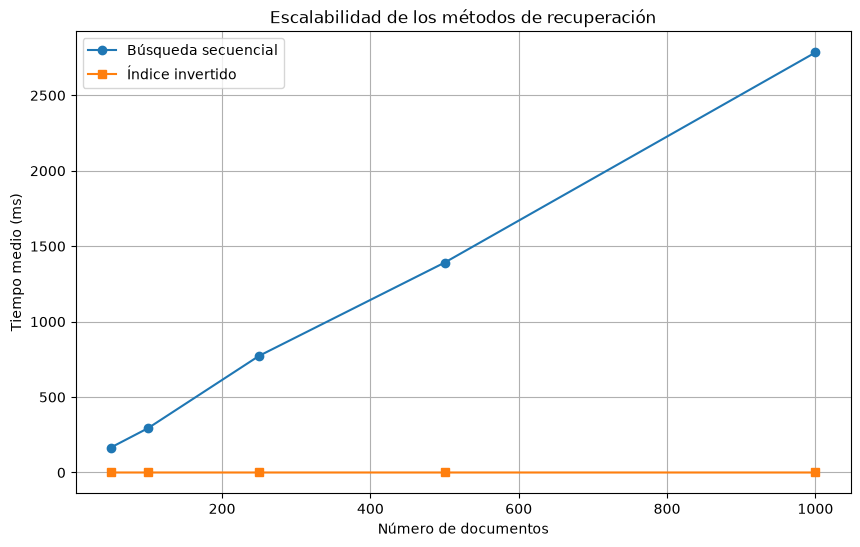

In [9]:
import matplotlib.pyplot as plt


# Tamaños del corpus.
tamanos = [50, 100, 250, 500, 1000]

# Término de consulta.
termino_experimento = "whale"

# Almacenar los resultados.
resultados_escalabilidad = []


# --------------------------------------------------
# Cargar una sola vez el conjunto más grande.
# --------------------------------------------------

corpus_base = cargar_subconjunto(
    libros_ordenados,
    max(tamanos)
)

if len(corpus_base) < max(tamanos):
    raise ValueError(
        f"Solo se cargaron {len(corpus_base)} documentos válidos. "
        f"Se necesitan {max(tamanos)} para completar el experimento."
    )


# --------------------------------------------------
# Ejecutar experimentos
# --------------------------------------------------

for n in tamanos:

    # Crear subconjunto conservando los IDs originales.
    corpus_n = dict(
        list(corpus_base.items())[:n]
    )

    # Número total de tokens.
    total_tokens = sum(
        len(tokens)
        for tokens in corpus_n.values()
    )

    # Construir índice invertido.
    inicio = time.perf_counter()

    indice_n = construir_indice(corpus_n)

    tiempo_construccion = (
        time.perf_counter() - inicio
    ) * 1000

    # Medir búsqueda secuencial.
    tiempo_sec = medir_tiempo(
        busqueda_secuencial,
        corpus_n,
        termino_experimento
    )

    # Medir búsqueda mediante índice.
    tiempo_ind = medir_tiempo(
        buscar_indice,
        indice_n,
        termino_experimento
    )

    # Comprobar que ambos algoritmos coinciden.
    resultado_sec = set(
        busqueda_secuencial(corpus_n, termino_experimento)
    )

    resultado_ind = buscar_indice(
        indice_n,
        termino_experimento
    )

    assert resultado_sec == resultado_ind

    # Guardar mediciones.
    resultados_escalabilidad.append({
        "documentos": n,
        "tokens": total_tokens,
        "secuencial": tiempo_sec,
        "indice": tiempo_ind,
        "construccion": tiempo_construccion
    })

    print(
        f"{n} documentos | "
        f"{total_tokens} tokens | "
        f"Secuencial: {tiempo_sec:.6f} ms | "
        f"Índice: {tiempo_ind:.6f} ms | "
        f"Construcción: {tiempo_construccion:.4f} ms"
    )


# --------------------------------------------------
# Preparar datos para la gráfica
# --------------------------------------------------

x = [
    resultado["documentos"]
    for resultado in resultados_escalabilidad
]

y_sec = [
    resultado["secuencial"]
    for resultado in resultados_escalabilidad
]

y_ind = [
    resultado["indice"]
    for resultado in resultados_escalabilidad
]


# --------------------------------------------------
# Graficar
# --------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    x,
    y_sec,
    marker="o",
    label="Búsqueda secuencial"
)

plt.plot(
    x,
    y_ind,
    marker="s",
    label="Índice invertido"
)

plt.xlabel("Número de documentos")

plt.ylabel("Tiempo medio (ms)")

plt.title("Escalabilidad de los métodos de recuperación")

plt.legend()

plt.grid(True)

plt.show()

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

BÚSQUEDA SECUENCIAL
t(n) = 2.74582729n + 38.12646075
R² = 0.999284

ÍNDICE INVERTIDO
t(n) = 0.00000108n + 0.00501693
R² = 0.083301


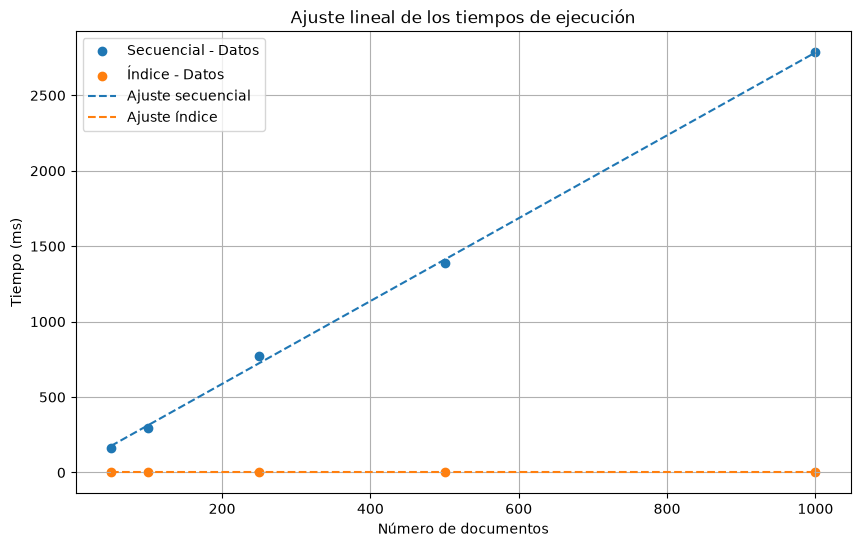

In [10]:
import numpy as np


# Convertir los resultados a arreglos NumPy.
n = np.array(x, dtype=float)

tiempos_sec = np.array(y_sec, dtype=float)

tiempos_ind = np.array(y_ind, dtype=float)


# --------------------------------------------------
# Ajuste lineal
# --------------------------------------------------

a_sec, b_sec = np.polyfit(
    n, tiempos_sec, 1
)

a_ind, b_ind = np.polyfit(
    n, tiempos_ind, 1
)


# --------------------------------------------------
# Funciones estimadas
# --------------------------------------------------

def modelo_secuencial(n):
    return a_sec * n + b_sec


def modelo_indice(n):
    return a_ind * n + b_ind


# Predicciones del modelo.
pred_sec = modelo_secuencial(n)

pred_ind = modelo_indice(n)


# --------------------------------------------------
# Coeficiente de determinación R²
# --------------------------------------------------

def calcular_r2(reales, predichos):

    ss_res = np.sum(
        (reales - predichos) ** 2
    )

    ss_tot = np.sum(
        (reales - np.mean(reales)) ** 2
    )

    if np.isclose(ss_tot, 0):
        return np.nan

    return 1 - (ss_res / ss_tot)


r2_sec = calcular_r2(
    tiempos_sec, pred_sec
)

r2_ind = calcular_r2(
    tiempos_ind, pred_ind
)


# --------------------------------------------------
# Mostrar funciones estimadas
# --------------------------------------------------

print("BÚSQUEDA SECUENCIAL")

print(
    f"t(n) = {a_sec:.8f}n + {b_sec:.8f}"
)

print(f"R² = {r2_sec:.6f}")


print("\nÍNDICE INVERTIDO")

print(
    f"t(n) = {a_ind:.8f}n + {b_ind:.8f}"
)

print(f"R² = {r2_ind:.6f}")


# --------------------------------------------------
# Representación gráfica
# --------------------------------------------------

n_linea = np.linspace(
    min(n),
    max(n),
    200
)

plt.figure(figsize=(10, 6))


# Datos experimentales.
plt.scatter(
    n,
    tiempos_sec,
    label="Secuencial - Datos"
)

plt.scatter(
    n,
    tiempos_ind,
    label="Índice - Datos"
)


# Funciones ajustadas.
plt.plot(
    n_linea,
    modelo_secuencial(n_linea),
    linestyle="--",
    label="Ajuste secuencial"
)

plt.plot(
    n_linea,
    modelo_indice(n_linea),
    linestyle="--",
    label="Ajuste índice"
)


plt.xlabel("Número de documentos")

plt.ylabel("Tiempo (ms)")

plt.title("Ajuste lineal de los tiempos de ejecución")

plt.legend()

plt.grid(True)

plt.show()